# 🔢 NumPy Tutorial
### A notebook that doubles as a *formatting cheat-sheet* for your own notes

> **How to use this file:** double-click any text cell to see the raw Markdown behind it,
> then press `Shift + Enter` to render it again. Copy whatever style you like into your own notes.

---

**Table of contents**

1. [Why NumPy?](#1.-Why-NumPy?)
2. [Creating arrays](#2.-Creating-arrays)
3. [Array attributes](#3.-Array-attributes)
4. [Indexing and slicing](#4.-Indexing-and-slicing)
5. [Operations and broadcasting](#5.-Operations-and-broadcasting)
6. [Aggregations](#6.-Aggregations)
7. [Reshaping](#7.-Reshaping)
8. [Boolean masking](#8.-Boolean-masking)
9. [Linear algebra](#9.-Linear-algebra)
10. [Plotting with Matplotlib](#10.-Plotting-with-Matplotlib)
11. [Practice questions](#11.-Practice-questions)
12. [Formatting features summary](#12.-Formatting-features-summary)

## 1. Why NumPy?

NumPy gives you the **`ndarray`**: a fast, fixed-type, n-dimensional array.

| Feature | Python `list` | NumPy `ndarray` |
|:--------|:-------------:|:---------------:|
| Element types | Mixed | One type (homogeneous) |
| Speed | Slower | Much faster (C under the hood) |
| Math on whole collection | ❌ needs loops | ✅ vectorised |
| Memory | More | Less |

<div style="background:#e8f4fd; border-left:5px solid #2196f3; padding:10px 14px; border-radius:4px;">
💡 <b>Tip:</b> This blue box is plain HTML inside a Markdown cell. Change the colours to make
<i>Note</i>, <i>Warning</i> and <i>Tip</i> boxes.
</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.4.4


Speed comparison using the **magic command** `%timeit` (magics start with `%` and only work in Jupyter):

In [2]:
py_list = list(range(1_000_000))
np_arr  = np.arange(1_000_000)

%timeit [x * 2 for x in py_list]
%timeit np_arr * 2

41.5 ms ± 3.24 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


575 μs ± 39.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## 2. Creating arrays

Common constructors:

- `np.array()` : from a Python list
- `np.zeros()`, `np.ones()`, `np.full()` : filled arrays
- `np.arange()`, `np.linspace()` : ranges
- `np.eye()` : identity matrix
- `np.random.*` : random numbers

In [3]:
a = np.array([1, 2, 3, 4])
b = np.array([[1, 2, 3],
              [4, 5, 6]])

print("1-D:", a)
print("2-D:\n", b)

1-D: [1 2 3 4]
2-D:
 [[1 2 3]
 [4 5 6]]


In [4]:
print("zeros  :", np.zeros(3))
print("ones   :\n", np.ones((2, 3)))
print("full   :", np.full(4, 7))
print("arange :", np.arange(0, 10, 2))
print("linspace:", np.linspace(0, 1, 5))
print("eye    :\n", np.eye(3))

zeros  : [0. 0. 0.]
ones   :
 [[1. 1. 1.]
 [1. 1. 1.]]
full   : [7 7 7 7]
arange : [0 2 4 6 8]
linspace: [0.   0.25 0.5  0.75 1.  ]
eye    :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [5]:
rng = np.random.default_rng(seed=42)   # seed makes results reproducible
rng.integers(1, 10, size=(3, 3))

array([[1, 7, 6],
       [4, 4, 8],
       [1, 7, 2]])

> The **last line** of a code cell is displayed automatically, even without `print()`.
> That is why the cell above shows its output.

## 3. Array attributes

| Attribute | Meaning |
|---|---|
| `.shape` | dimensions as a tuple |
| `.ndim` | number of axes |
| `.size` | total number of elements |
| `.dtype` | data type of elements |

In [6]:
m = np.array([[1, 2, 3], [4, 5, 6]])
print("shape:", m.shape)
print("ndim :", m.ndim)
print("size :", m.size)
print("dtype:", m.dtype)

shape: (2, 3)
ndim : 2
size : 6
dtype: int64


## 4. Indexing and slicing

Syntax: `arr[start:stop:step]` where **stop is excluded**.

For a 2-D array: `arr[row_slice, col_slice]`.

In [7]:
x = np.arange(10, 100, 10)
print(x)
print("x[2]     =", x[2])
print("x[-1]    =", x[-1])
print("x[2:5]   =", x[2:5])
print("x[::2]   =", x[::2])
print("x[::-1]  =", x[::-1])

[10 20 30 40 50 60 70 80 90]
x[2]     = 30
x[-1]    = 90
x[2:5]   = [30 40 50]
x[::2]   = [10 30 50 70 90]
x[::-1]  = [90 80 70 60 50 40 30 20 10]


In [8]:
g = np.arange(1, 17).reshape(4, 4)
print(g)
print("\nrow 1       :", g[1])
print("column 2    :", g[:, 2])
print("centre 2x2  :\n", g[1:3, 1:3])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]

row 1       : [5 6 7 8]
column 2    : [ 3  7 11 15]
centre 2x2  :
 [[ 6  7]
 [10 11]]


<details>
<summary><b>Click to expand: slices are views, not copies</b></summary>

<br>

A slice shares memory with the original array. Changing the slice changes the original.
Use `.copy()` if you want an independent array.

```python
s = x[1:3]
s[0] = 999      # x changes too!
t = x[1:3].copy()
```

</details>

In [9]:
orig = np.array([1, 2, 3, 4, 5])
view = orig[1:3]
view[0] = 999
print("orig after editing view:", orig)

orig after editing view: [  1 999   3   4   5]


## 5. Operations and broadcasting

Arithmetic is **element-wise**:

$$ c_i = a_i + b_i $$

**Broadcasting** lets NumPy combine arrays of different shapes by stretching the smaller one,
provided that, comparing shapes from the right, each pair of dimensions is equal or one of them is 1.

In [10]:
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])

print("a + b  =", a + b)
print("a * b  =", a * b)
print("a ** 2 =", a ** 2)
print("a * 5  =", a * 5)       # scalar is broadcast
print("sqrt   =", np.sqrt(a))

a + b  = [11 22 33]
a * b  = [10 40 90]
a ** 2 = [1 4 9]
a * 5  = [ 5 10 15]
sqrt   = [1.         1.41421356 1.73205081]


In [11]:
matrix = np.array([[1, 2, 3],
                   [4, 5, 6]])
row = np.array([10, 20, 30])

print("(2,3) + (3,) ->\n", matrix + row)

(2,3) + (3,) ->
 [[11 22 33]
 [14 25 36]]


Visual rule of thumb:

```
matrix : (2, 3)
row    :    (3,)   ->  treated as (1, 3)  ->  stretched to (2, 3)
```

## 6. Aggregations

`sum`, `mean`, `std`, `min`, `max`, `argmin`, `argmax`, `cumsum`.

The **`axis`** argument chooses the direction:
- `axis=0` collapses **rows** (result has one value per column)
- `axis=1` collapses **columns** (result has one value per row)

The mean is

$$ \bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i $$

and the standard deviation is

$$ \sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2} $$

In [12]:
scores = np.array([[70, 85, 90],
                   [60, 75, 80],
                   [95, 88, 92]])

print("total          :", scores.sum())
print("column sums    :", scores.sum(axis=0))
print("row means      :", scores.mean(axis=1))
print("max / argmax   :", scores.max(), "/", scores.argmax())
print("std            :", round(scores.std(), 3))
print("cumulative sum :", np.cumsum([1, 2, 3, 4]))

total          : 735
column sums    : [225 248 262]
row means      : [81.66666667 71.66666667 91.66666667]
max / argmax   : 95 / 6
std            : 10.842
cumulative sum : [ 1  3  6 10]


## 7. Reshaping

| Function | What it does |
|---|---|
| `reshape(r, c)` | new shape, same data (use `-1` to auto-infer one dimension) |
| `flatten()` | 1-D copy |
| `.T` | transpose |
| `np.vstack`, `np.hstack` | stack arrays |

In [13]:
r = np.arange(12)
print(r.reshape(3, 4))
print()
print(r.reshape(2, -1).shape)      # -1 means "figure it out"
print()
print(np.vstack([np.array([1, 2]), np.array([3, 4])]))
print(np.hstack([np.array([1, 2]), np.array([3, 4])]))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2, 6)

[[1 2]
 [3 4]]
[1 2 3 4]


## 8. Boolean masking

Comparisons return an array of `True`/`False`. Using that array as an index **filters** the data.

In [14]:
data = np.array([12, 7, 25, 3, 18, 9, 30])

mask = data > 10
print("mask    :", mask)
print("filtered:", data[mask])
print("even    :", data[data % 2 == 0])
print("10 < x < 25:", data[(data > 10) & (data < 25)])   # use & and |, not 'and'/'or'

mask    : [ True False  True False  True False  True]
filtered: [12 25 18 30]
even    : [12 18 30]
10 < x < 25: [12 18]


In [15]:
# np.where: if-else for arrays
np.where(data > 10, "big", "small")

array(['big', 'small', 'big', 'small', 'big', 'small', 'big'], dtype='<U5')

<div style="background:#fff4e5; border-left:5px solid #ff9800; padding:10px 14px; border-radius:4px;">
⚠️ <b>Warning:</b> combine conditions with <code>&amp;</code>, <code>|</code> and put each condition in
<b>parentheses</b>. Python's <code>and</code>/<code>or</code> raise an error on arrays.
</div>

## 9. Linear algebra

Matrix product: $C = AB$ where $C_{ij} = \sum_k A_{ik}B_{kj}$

Solving a system $Ax = b$:

$$
\begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}
\begin{bmatrix} x \\ y \end{bmatrix}
=
\begin{bmatrix} 5 \\ 10 \end{bmatrix}
$$

In [16]:
A = np.array([[2, 1],
              [1, 3]])
b = np.array([5, 10])

print("A @ A     =\n", A @ A)
print("det(A)    =", round(np.linalg.det(A), 3))
print("inv(A)    =\n", np.linalg.inv(A))
print("solution  =", np.linalg.solve(A, b))

A @ A     =
 [[ 5  5]
 [ 5 10]]
det(A)    = 5.0
inv(A)    =
 [[ 0.6 -0.2]
 [-0.2  0.4]]
solution  = [1. 3.]


## 10. Plotting with Matplotlib

Plots appear **inline**, right below the cell that creates them.

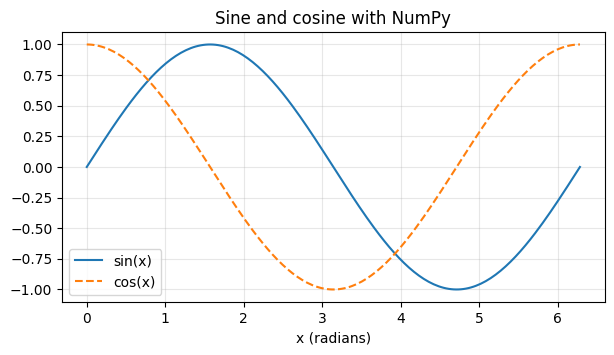

In [17]:
x = np.linspace(0, 2 * np.pi, 200)

plt.figure(figsize=(7, 3.5))
plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.cos(x), label="cos(x)", linestyle="--")
plt.title("Sine and cosine with NumPy")
plt.xlabel("x (radians)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Practice questions

- [ ] **Q1.** Create a 5×5 array of zeros, then set the border to 1.
- [ ] **Q2.** From `np.arange(1, 21)` extract all numbers divisible by 3.
- [ ] **Q3.** Normalise an array so its values lie between 0 and 1.

<details>
<summary><b>Show solutions</b></summary>

```python
# Q1
z = np.zeros((5, 5)); z[0, :] = z[-1, :] = z[:, 0] = z[:, -1] = 1

# Q2
n = np.arange(1, 21); n[n % 3 == 0]

# Q3
a = np.array([4, 8, 15, 16, 23, 42]); (a - a.min()) / (a.max() - a.min())
```

</details>

In [18]:
# Your workspace: try Q1 here

## 12. Formatting features summary

A quick reference of everything used in this notebook.

| Feature | Syntax |
|---|---|
| Headings | `# H1`, `## H2`, `### H3` |
| Bold / italic / both | `**bold**`, `*italic*`, `***both***` |
| `Inline code` | `` `code` `` |
| Code block | triple backticks + language |
| Bullet list | `- item` |
| Numbered list | `1. item` |
| Checkbox | `- [ ] task` / `- [x] done` |
| Blockquote | `> text` |
| Link | `[text](https://numpy.org)` |
| Internal link | `[text](#Heading-With-Dashes)` |
| Inline math | `$x^2$` |
| Display math | `$$ ... $$` |
| Horizontal rule | `---` |
| Collapsible section | `<details><summary>..</summary>..</details>` |
| Coloured box | HTML `<div style="...">` |
| Image | `![alt](path_or_url)` |
| Magic commands | `%timeit`, `%%time`, `%matplotlib inline` |

Other handy things:

- **Cell types:** *Code*, *Markdown* and *Raw* (the cell below is a Raw cell, it is never rendered or executed).
- **Shortcuts:** `Esc` command mode, `M` to Markdown, `Y` to Code, `A`/`B` insert above/below, `DD` delete cell.

Strikethrough: ~~old idea~~ and an emoji ✅

📚 Docs: [numpy.org/doc](https://numpy.org/doc/)